<a href="https://colab.research.google.com/github/dshukla1410/dshukla1410.github.io/blob/main/Nov11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dataset dimensions: (1232, 4)

Column names:
['sample', 'OS.time', 'OS', '_PATIENT']

First five rows:


,sample,OS.time,OS,_PATIENT
0,TCGA-C8-A275-01A,1.0,0,TCGA-C8-A275
1,TCGA-AC-A7VC-01A,1.0,0,TCGA-AC-A7VC
2,TCGA-BH-A1F8-01A,1.0,1,TCGA-BH-A1F8
3,TCGA-BH-A1F8-11B,1.0,1,TCGA-BH-A1F8
4,TCGA-PL-A8LX-01A,5.0,0,TCGA-PL-A8LX



Cleaned dataset:
   OS.time  OS
0      1.0   0
1      1.0   0
2      1.0   1
3      1.0   1
4      5.0   0

Number of patients: 1232
Deaths (events): 201
Censored observations: 1031


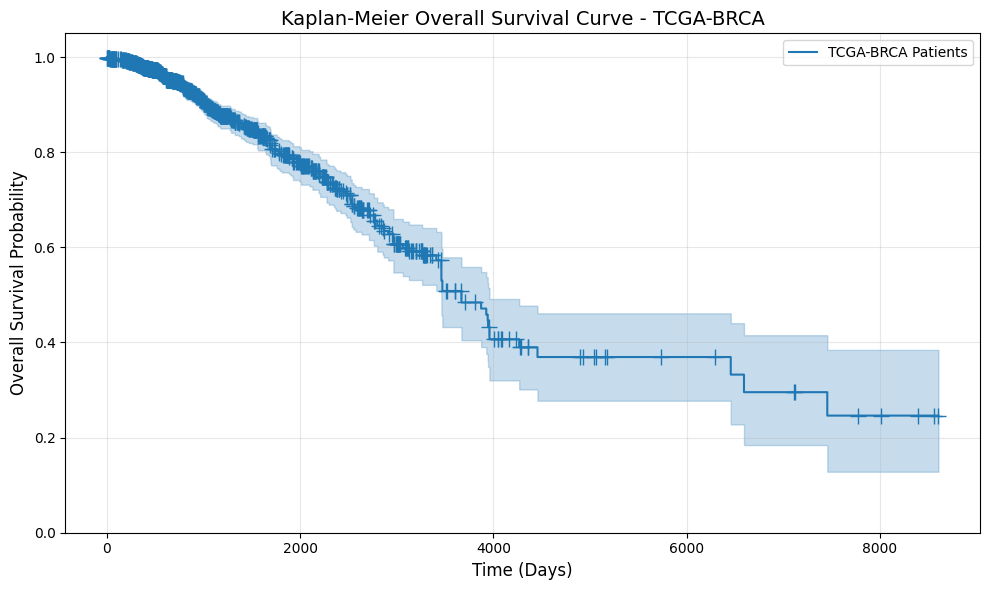


Median Overall Survival Time:
3669.0 days

Survival Probabilities:
365 days: 0.979
1095 days: 0.889
1825 days: 0.794


In [4]:

# ==========================================
# KAPLAN-MEIER SURVIVAL ANALYSIS
# TCGA-BRCA (Breast Cancer)
# ==========================================

# 1. Install required libraries
!pip install lifelines -q

# 2. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# 3. Download and load the dataset
url = "https://gdc-hub.s3.us-east-1.amazonaws.com/download/TCGA-BRCA.survival.tsv.gz"

df = pd.read_csv(url, sep="\t", compression="gzip")

# 4. Examine the dataset
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

# 5. Select overall survival information
# OS.time = overall survival time
# OS = overall survival event status

time_col = "OS.time"
event_col = "OS"

if time_col not in df.columns or event_col not in df.columns:
    raise ValueError(
        "Expected OS.time and OS columns were not found. "
        "Check the column names printed above."
    )

# 6. Prepare survival data
survival_df = df[[time_col, event_col]].copy()

# Convert survival time to numeric
survival_df[time_col] = pd.to_numeric(
    survival_df[time_col], errors="coerce"
)

# Convert event status to numeric or recognize text labels
def convert_event(value):
    if pd.isna(value):
        return np.nan

    # Handle numeric event status
    try:
        number = float(value)
        if number in (0, 1):
            return int(number)
    except (ValueError, TypeError):
        pass

    # Handle labels such as 1:DECEASED or 0:LIVING
    value = str(value).strip().upper()

    if value.startswith("1"):
        return 1
    if value.startswith("0"):
        return 0
    if "DECEASED" in value or "DEAD" in value:
        return 1
    if "LIVING" in value or "ALIVE" in value:
        return 0

    return np.nan

survival_df[event_col] = survival_df[event_col].apply(
    convert_event
)

# Remove missing and invalid observations
survival_df = survival_df.dropna()

survival_df = survival_df[
    survival_df[time_col] >= 0
]

survival_df[event_col] = survival_df[event_col].astype(int)

# Check event status
print("\nCleaned dataset:")
print(survival_df.head())

print("\nNumber of patients:", len(survival_df))
print("Deaths (events):", survival_df[event_col].sum())
print("Censored observations:",
      (survival_df[event_col] == 0).sum())

# 7. Fit Kaplan-Meier model
kmf = KaplanMeierFitter()

kmf.fit(
    durations=survival_df[time_col],
    event_observed=survival_df[event_col],
    label="TCGA-BRCA Patients"
)

# 8. Plot Kaplan-Meier survival curve
plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True,
    show_censors=True
)

plt.title(
    "Kaplan-Meier Overall Survival Curve - TCGA-BRCA",
    fontsize=14
)

plt.xlabel("Time (Days)", fontsize=12)
plt.ylabel("Overall Survival Probability", fontsize=12)

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# 9. Display median survival time
print("\nMedian Overall Survival Time:")
print(kmf.median_survival_time_, "days")

# 10. Display survival probabilities
print("\nSurvival Probabilities:")
for t in [365, 1095, 1825]:
    print(
        f"{t} days: "
        f"{kmf.predict(t):.3f}"
    )
